**Problem Description**:
The goal of this project is to study the relationship between students’ daily study hours and their exam scores, and to determine whether study hours can be used to predict exam performance.

**Solution**:
The dataset is explored using histograms and correlation analysis. study_hours_per_day is selected because it has a strong relationship with exam_score. A Linear Regression model is then trained using these variables and used to predict a student’s exam score based on study hours.

  student_id  age  gender  study_hours_per_day  social_media_hours  \
0      S1000   23  Female                  0.0                 1.2   
1      S1001   20  Female                  6.9                 2.8   
2      S1002   21    Male                  1.4                 3.1   
3      S1003   23  Female                  1.0                 3.9   
4      S1004   19  Female                  5.0                 4.4   

   netflix_hours part_time_job  attendance_percentage  sleep_hours  \
0            1.1            No                   85.0          8.0   
1            2.3            No                   97.3          4.6   
2            1.3            No                   94.8          8.0   
3            1.0            No                   71.0          9.2   
4            0.5            No                   90.9          4.9   

  diet_quality  exercise_frequency parental_education_level internet_quality  \
0         Fair                   6                   Master          Average  

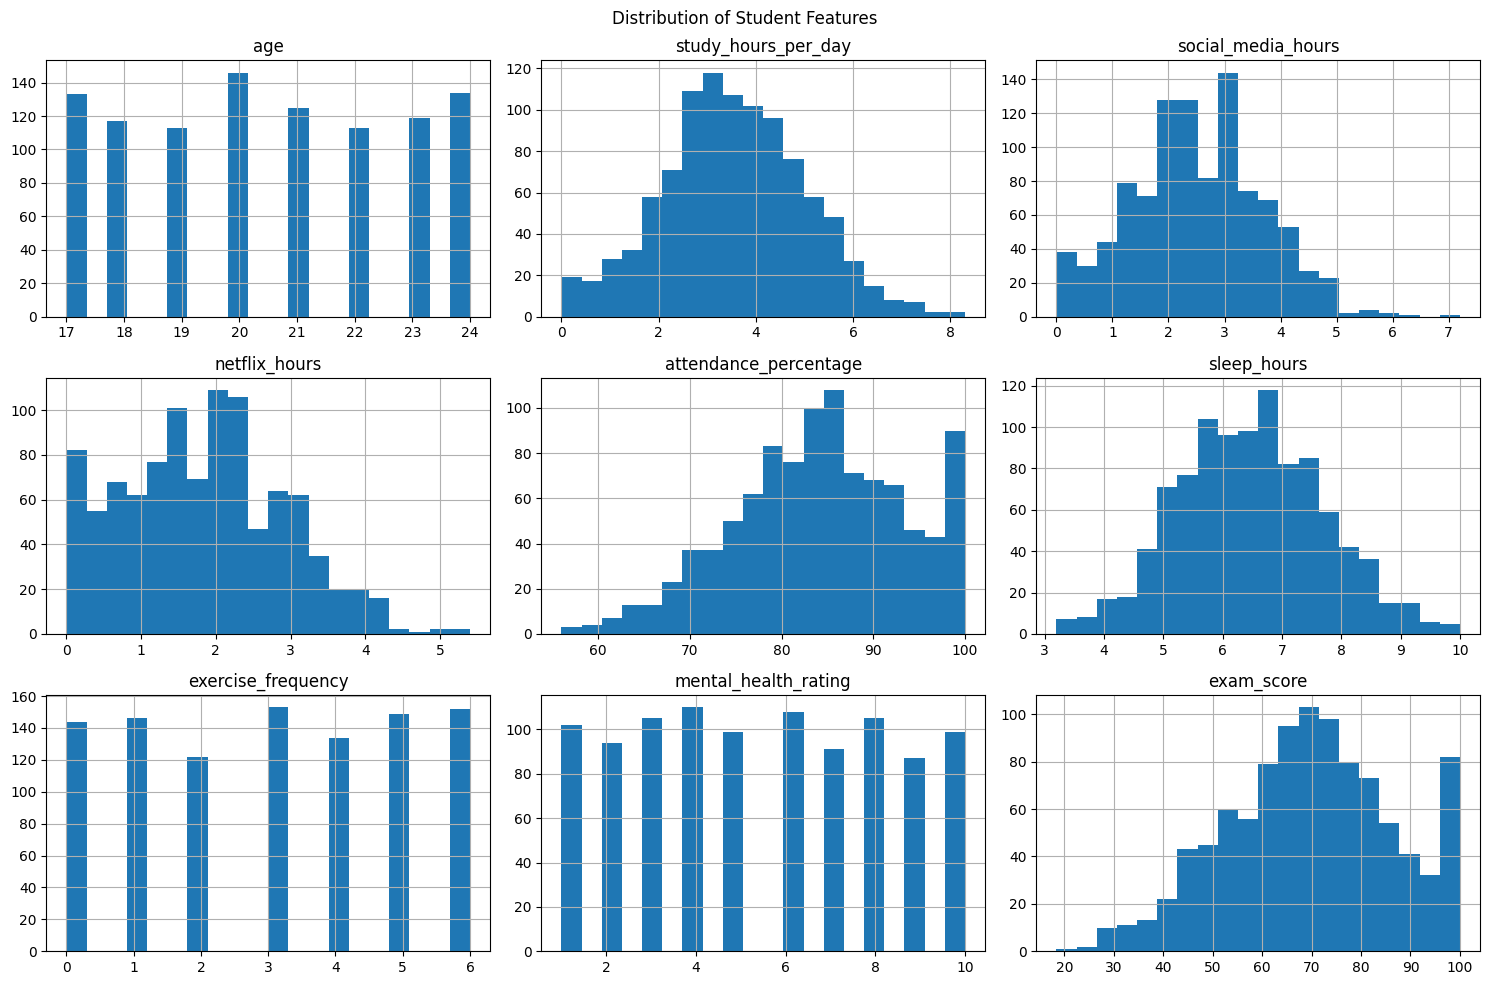


Correlation with Exam Score:
exam_score               1.000000
study_hours_per_day      0.825419
mental_health_rating     0.321523
exercise_frequency       0.160107
sleep_hours              0.121683
attendance_percentage    0.089836
age                     -0.008907
social_media_hours      -0.166733
netflix_hours           -0.171779
Name: exam_score, dtype: float64


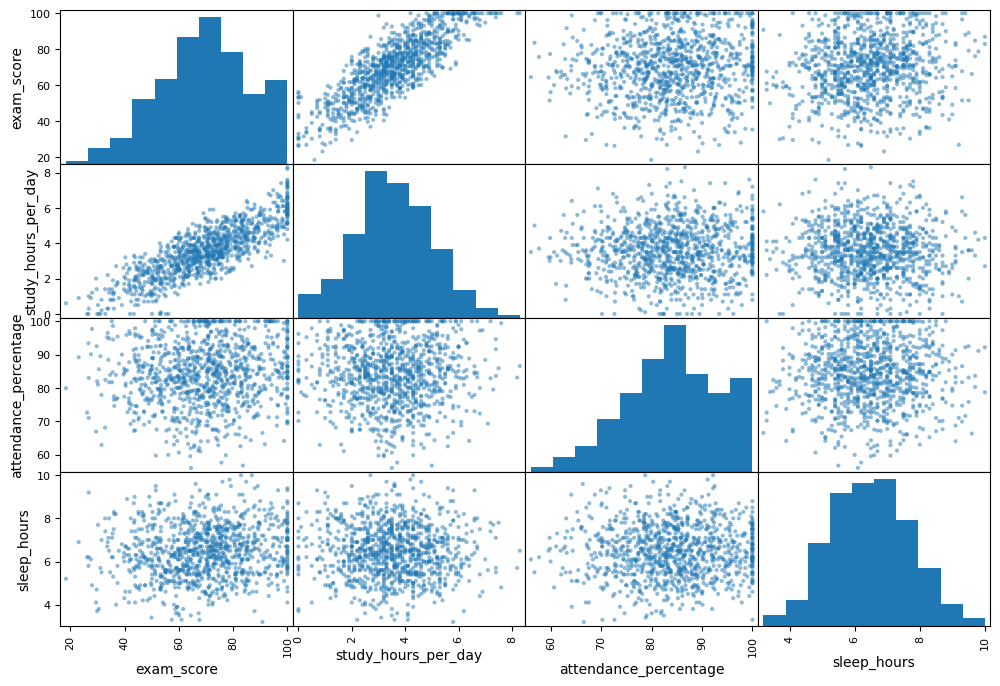

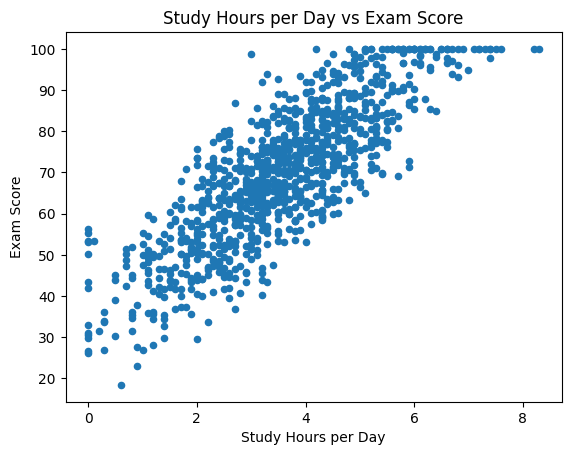


Predicted exam score for a student who studies 5 hours per day:
[[83.36141406]]


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn.linear_model
from pandas.plotting import scatter_matrix


# 1. Load the data
dataset = pd.read_csv("student_habits_performance.csv")


# 2. Display and understand the dataset
print(dataset.head())

print("Dataset shape:", dataset.shape)

dataset.info()

print(dataset.describe())


# 3. Plot histograms of the numerical features
dataset.hist(bins=20, figsize=(15, 10))

plt.suptitle("Distribution of Student Features")
plt.tight_layout()

plt.savefig("student_features_histogram.png")

plt.show()


# 4. Check correlation with exam score
corr_matrix = dataset.corr(numeric_only=True)

print("\nCorrelation with Exam Score:")
print(corr_matrix["exam_score"].sort_values(ascending=False))


# 5. Visualize correlations using a scatter matrix
attributes = [
    "exam_score",
    "study_hours_per_day",
    "attendance_percentage",
    "sleep_hours"
]

scatter_matrix(
    dataset[attributes],
    figsize=(12, 8)
)

plt.savefig("correlation_scatter_matrix.png")

plt.show()


# 6. Select the two variables based on correlation
X = np.c_[dataset["study_hours_per_day"]]
y = np.c_[dataset["exam_score"]]


# 7. Plot the two selected variables
dataset.plot(
    kind="scatter",
    x="study_hours_per_day",
    y="exam_score"
)

plt.title("Study Hours per Day vs Exam Score")
plt.xlabel("Study Hours per Day")
plt.ylabel("Exam Score")

plt.savefig("study_hours_vs_exam_score.png")

plt.show()


# 8. Select a Linear Regression model
model = sklearn.linear_model.LinearRegression()


# 9. Train the model
model.fit(X, y)


# 10. Make a prediction
# Predict the exam score for a student who studies 5 hours per day
X_new = [[5]]

prediction = model.predict(X_new)

print("\nPredicted exam score for a student who studies 5 hours per day:")
print(prediction)